## 1. Подготовка данных и построение классификационных моделей

В работе используется набор данных **Communities and Crime Unnormalized**, содержащий социально-экономические, демографические и криминологические характеристики населённых пунктов США.

Целью является классификация населённых пунктов по уровню насильственной преступности на основе их социально-экономических и демографических показателей.

Первоначально целевая переменная `ViolentCrimesPerPop` представляет собой количественный показатель числа насильственных преступлений на 100 000 жителей. Для решения задачи бинарной классификации она преобразуется в две категории:

- **Класс 0** — уровень преступности не превышает медианное значение обучающей выборки.
- **Класс 1** — уровень преступности превышает медианное значение обучающей выборки.

Данные разделяются на обучающую (70%) и тестовую (30%) выборки

Размер датасета: (2215, 147)

Первые 5 строк (ключевые столбцы):
             communityname  population  medIncome  ViolentCrimesPerPop
0  BerkeleyHeightstownship       11980      75122                41.02
1           Marpletownship       23123      47917               127.56
2               Tigardcity       29344      35669               218.59
3         Gloversvillecity       16656      20580               306.64
4              Bemidjicity       11245      17390                  NaN

Топ столбцов с пропусками:
PctPolicBlack          1872
PolicReqPerOffic       1872
PolicPerPop            1872
PolicCars              1872
PolicOperBudg          1872
LemasPctPolicOnPatr    1872
PolicAveOTWorked       1872
LemasGangUnitDeploy    1872
PolicBudgPerPop        1872
PctPolicWhite          1872
dtype: int64

Статистика целевой переменной (ViolentCrimesPerPop):
count    1994.000000
mean      589.078922
std       614.784518
min         0.000000
25%       161.700000
50%       374.060000
75%     

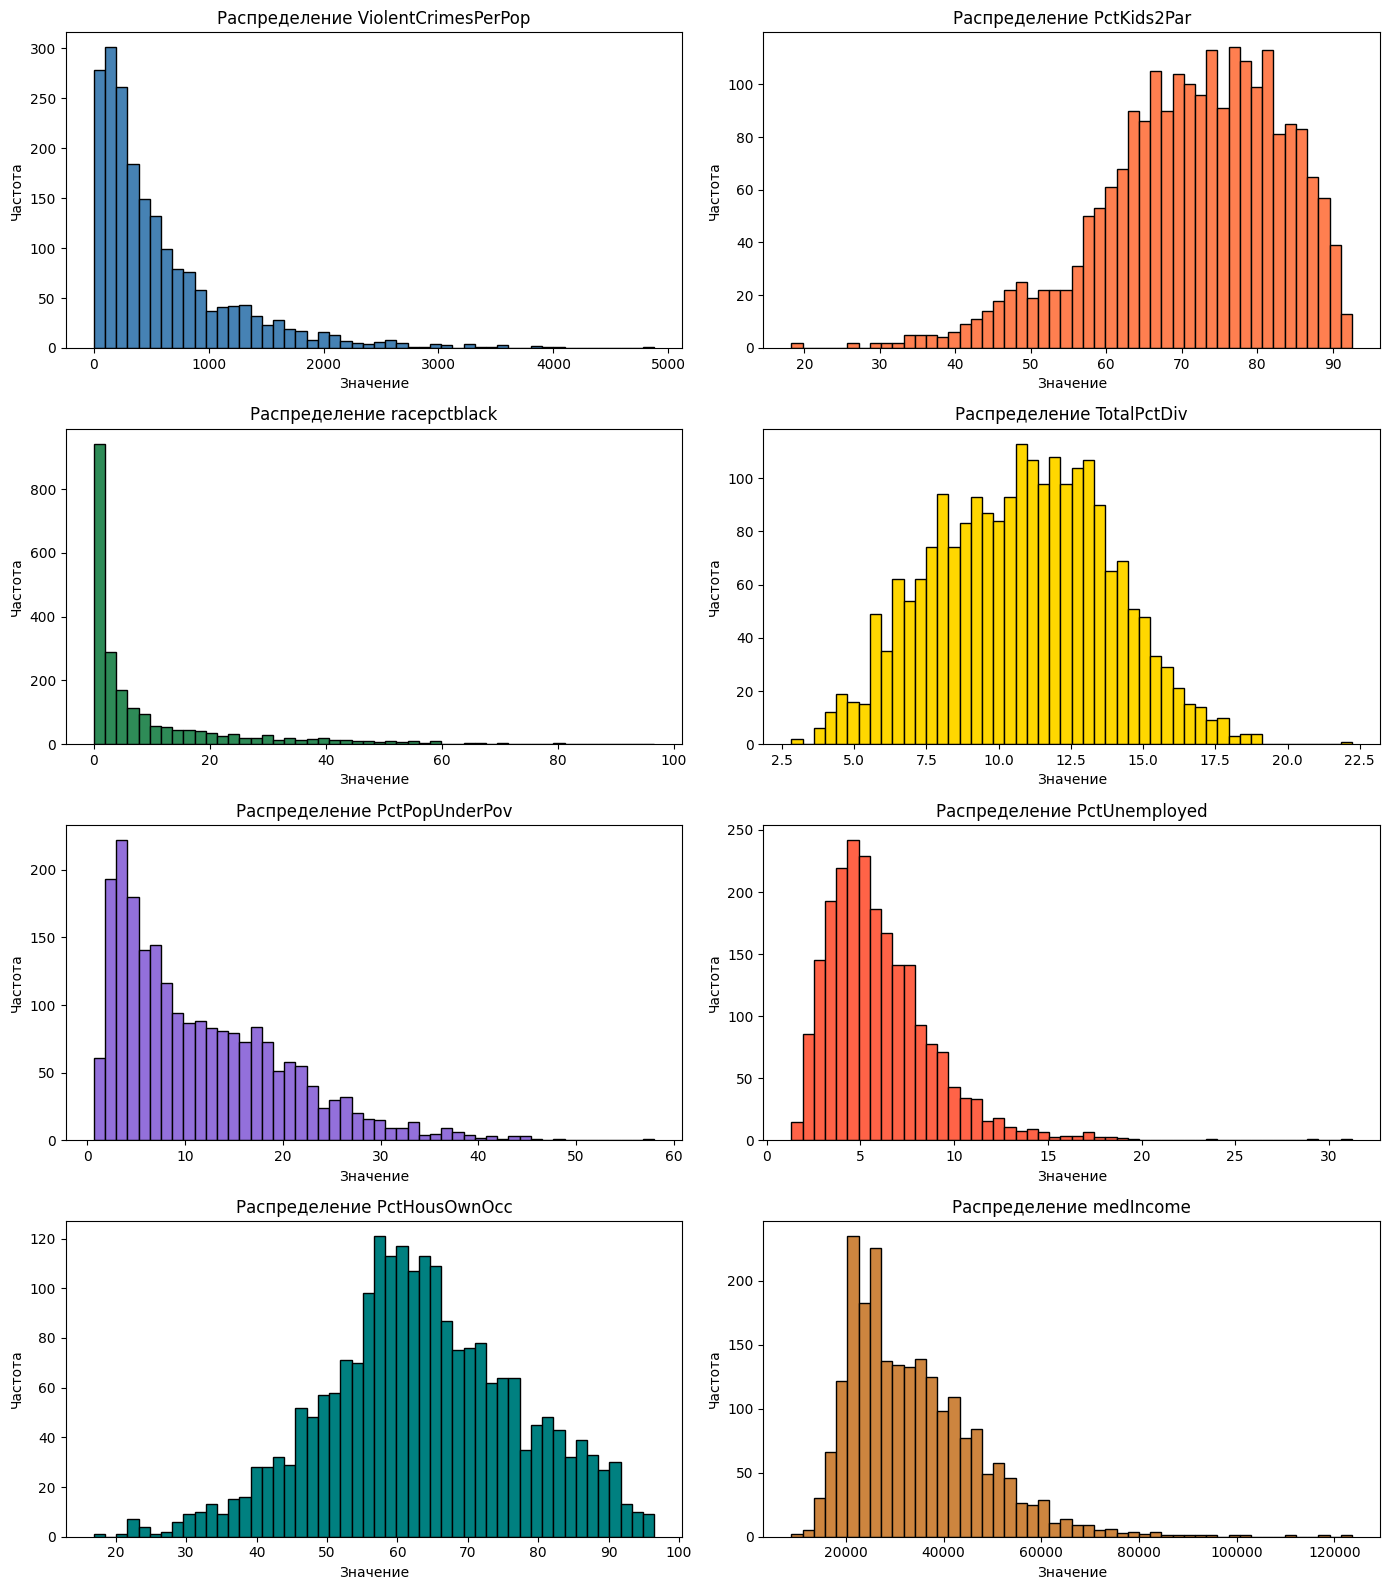


ПОДГОТОВКА ДАННЫХ
Количество наблюдений: 1994
Количество исходных признаков: 124

Порог преступности: 369.3
Класс 0 — низкий уровень преступности
Класс 1 — высокий уровень преступности

Распределение классов (обучение):
ViolentCrimesPerPop
0    698
1    697
Name: count, dtype: int64

Распределение классов (тест):
ViolentCrimesPerPop
0    290
1    309
Name: count, dtype: int64

Удалено признаков: 22
Осталось признаков: 102


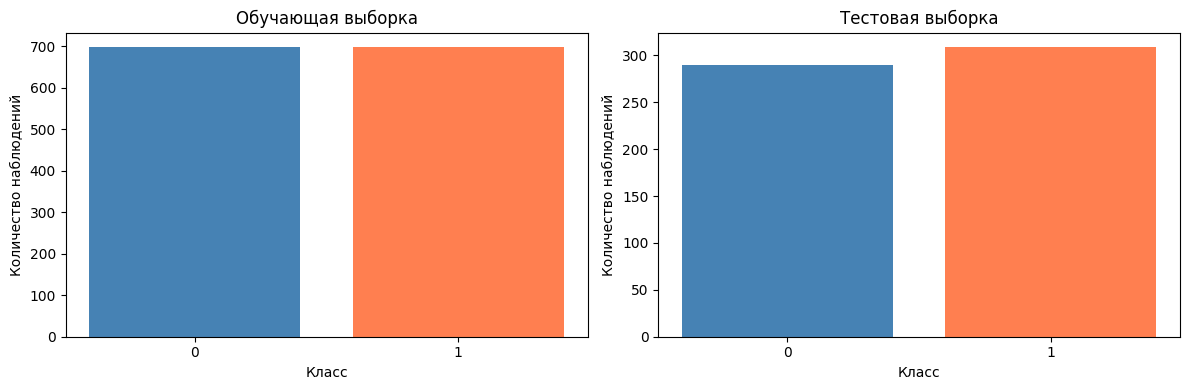

Размер обучающей выборки: (1395, 102)
Размер тестовой выборки: (599, 102)
Количество обученных моделей: 8
Модели: ['GaussianNB', 'MultinomialNB', 'ComplementNB', 'BernoulliNB', 'Decision Tree', 'LDA', 'SVM', 'kNN']


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, Binarizer
from sklearn.naive_bayes import (
    GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

file_path = "data/DATASET.txt"

df = pd.read_csv(file_path, header=None, na_values="?")

column_names = [
    'communityname', 'State', 'countyCode', 'communityCode', 'fold',
    'population', 'householdsize', 'racepctblack', 'racePctWhite',
    'racePctAsian', 'racePctHisp', 'agePct12t21', 'agePct12t29',
    'agePct16t24', 'agePct65up', 'numbUrban', 'pctUrban',
    'medIncome', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc',
    'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc',
    'perCapInc', 'whitePerCap', 'blackPerCap', 'indianPerCap',
    'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'NumUnderPov',
    'PctPopUnderPov', 'PctLess9thGrade', 'PctNotHSGrad',
    'PctBSorMore', 'PctUnemployed', 'PctEmploy', 'PctEmplManu',
    'PctEmplProfServ', 'PctOccupManu', 'PctOccupMgmtProf',
    'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv',
    'TotalPctDiv', 'PersPerFam', 'PctFam2Par', 'PctKids2Par',
    'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMomYoungKids',
    'PctWorkMom', 'NumKidsBornNeverMar', 'PctKidsBornNeverMar',
    'NumImmig', 'PctImmigRecent', 'PctImmigRec5',
    'PctImmigRec8', 'PctImmigRec10', 'PctRecentImmig',
    'PctRecImmig5', 'PctRecImmig8', 'PctRecImmig10',
    'PctSpeakEnglOnly', 'PctNotSpeakEnglWell',
    'PctLargHouseFam', 'PctLargHouseOccup',
    'PersPerOccupHous', 'PersPerOwnOccHous',
    'PersPerRentOccHous', 'PctPersOwnOccup',
    'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR',
    'HousVacant', 'PctHousOccup', 'PctHousOwnOcc',
    'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt',
    'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart',
    'OwnOccMedVal', 'OwnOccHiQuart', 'OwnOccQrange',
    'RentLowQ', 'RentMedian', 'RentHighQ', 'RentQrange',
    'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc',
    'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet',
    'PctForeignBorn', 'PctBornSameState', 'PctSameHouse85',
    'PctSameCity85', 'PctSameState85', 'LemasSwornFT',
    'LemasSwFTPerPop', 'LemasSwFTFieldOps',
    'LemasSwFTFieldPerPop', 'LemasTotalReq',
    'LemasTotReqPerPop', 'PolicReqPerOffic', 'PolicPerPop',
    'RacialMatchCommPol', 'PctPolicWhite', 'PctPolicBlack',
    'PctPolicHisp', 'PctPolicAsian', 'PctPolicMinor',
    'OfficAssgnDrugUnits', 'NumKindsDrugsSeiz',
    'PolicAveOTWorked', 'LandArea', 'PopDens',
    'PctUsePubTrans', 'PolicCars', 'PolicOperBudg',
    'LemasPctPolicOnPatr', 'LemasGangUnitDeploy',
    'LemasPctOfficDrugUn', 'PolicBudgPerPop',
    'murders', 'murdPerPop', 'rapes', 'rapesPerPop',
    'robberies', 'robbbPerPop', 'assaults', 'assaultPerPop',
    'burglaries', 'burglPerPop', 'larcenies', 'larcPerPop',
    'autoTheft', 'autoTheftPerPop', 'arsons', 'arsonsPerPop',
    'ViolentCrimesPerPop', 'nonViolPerPop'
]

df.columns = column_names

print(f"Размер датасета: {df.shape}")

print("\nПервые 5 строк (ключевые столбцы):")
print(
    df[
        ['communityname', 'population',
         'medIncome', 'ViolentCrimesPerPop']
    ].head()
)

print("\nТоп столбцов с пропусками:")
missing = df.isnull().sum().sort_values(ascending=False)
print(missing.head(10))

target = "ViolentCrimesPerPop"

print(f"\nСтатистика целевой переменной ({target}):")
print(df[target].describe())

key_features = [
    'PctKids2Par',
    'racepctblack',
    'TotalPctDiv',
    'PctPopUnderPov',
    'PctUnemployed',
    'PctHousOwnOcc',
    'medIncome'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

axes[0].hist(
    df[target].dropna(),
    bins=50,
    color='steelblue',
    edgecolor='black'
)
axes[0].set_title(f'Распределение {target}')
axes[0].set_xlabel('Значение')
axes[0].set_ylabel('Частота')

colors = [
    'coral', 'seagreen', 'gold', 'mediumpurple',
    'tomato', 'teal', 'peru'
]

for i, feat in enumerate(key_features):
    axes[i + 1].hist(
        df[feat].dropna(),
        bins=50,
        color=colors[i],
        edgecolor='black'
    )
    axes[i + 1].set_title(f'Распределение {feat}')
    axes[i + 1].set_xlabel('Значение')
    axes[i + 1].set_ylabel('Частота')

plt.tight_layout()
plt.show()

data = df.dropna(subset=[target]).copy()

service_columns = [
    "communityname", "State", "countyCode",
    "communityCode", "fold"
]

crime_columns = [
    "murders", "murdPerPop", "rapes", "rapesPerPop",
    "robberies", "robbbPerPop", "assaults", "assaultPerPop",
    "burglaries", "burglPerPop", "larcenies", "larcPerPop",
    "autoTheft", "autoTheftPerPop", "arsons",
    "arsonsPerPop", "nonViolPerPop"
]

X = data.drop(
    columns=service_columns + crime_columns + [target]
)

X = X.apply(pd.to_numeric, errors="coerce")
y_raw = data[target].astype(float)

print("\nПОДГОТОВКА ДАННЫХ")
print("Количество наблюдений:", len(X))
print("Количество исходных признаков:", X.shape[1])

X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X,
    y_raw,
    test_size=0.3,
    random_state=42
)

threshold = y_train_raw.median()

y_train = (y_train_raw > threshold).astype(int)
y_test = (y_test_raw > threshold).astype(int)

print("\nПорог преступности:", round(threshold, 2))
print("Класс 0 — низкий уровень преступности")
print("Класс 1 — высокий уровень преступности")

print("\nРаспределение классов (обучение):")
print(y_train.value_counts().sort_index())

print("\nРаспределение классов (тест):")
print(y_test.value_counts().sort_index())

missing_ratio = X_train.isna().mean()
columns_to_drop = missing_ratio[missing_ratio > 0.5].index

X_train = X_train.drop(columns=columns_to_drop)
X_test = X_test.drop(columns=columns_to_drop)

print("\nУдалено признаков:", len(columns_to_drop))
print("Осталось признаков:", X_train.shape[1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, y, title in zip(
    axes,
    [y_train, y_test],
    ["Обучающая выборка", "Тестовая выборка"]
):

    counts = y.value_counts().sort_index()

    ax.bar(
        counts.index.astype(str),
        counts.values,
        color=["steelblue", "coral"]
    )

    ax.set_title(title)
    ax.set_xlabel("Класс")
    ax.set_ylabel("Количество наблюдений")

plt.tight_layout()
plt.show()

def make_classifier(name, classifier):

    if name in ["MultinomialNB", "ComplementNB"]:
        scaler = MinMaxScaler()
        binary = "passthrough"

    elif name == "BernoulliNB":
        scaler = StandardScaler()
        binary = Binarizer(threshold=0.0)

    elif name == "Decision Tree":
        scaler = "passthrough"
        binary = "passthrough"

    else:
        scaler = StandardScaler()
        binary = "passthrough"

    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", scaler),
        ("binary", binary),
        ("model", classifier)
    ])

classifiers = {
    "GaussianNB": GaussianNB(),

    "MultinomialNB": MultinomialNB(),

    "ComplementNB": ComplementNB(),

    "BernoulliNB": BernoulliNB(binarize=None),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "LDA": LinearDiscriminantAnalysis(),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "kNN": KNeighborsClassifier()
}

models = {}

for name, classifier in classifiers.items():

    model = make_classifier(name, classifier)

    model.fit(X_train, y_train)

    models[name] = model

print("Размер обучающей выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Количество обученных моделей:", len(models))
print("Модели:", list(models.keys()))


Исходный набор содержит *2215 наблюдений и 147 столбцов*. Для целевой переменной `ViolentCrimesPerPop`

Наибольшее число пропусков обнаружено в характеристиках полиции: по 1872 пропуска в каждом из показанных столбцов. После удаления признаков, у которых в обучающей выборке отсутствует более 50% значений, исключены 22 столбца и оставлены *102 признака*. Остальные пропуски заполняются медианой внутри конвейера, поэтому параметры заполнения определяются только по обучающим данным.

Порог бинаризации равен *369,3* и рассчитан как медиана целевой переменной на обучающей выборке.

Итоговые размеры составляют *1395 × 102* для обучения и *599 × 102* для тестирования.

# 2. Оценка и сравнение качества классификаторов

Для оценки качества обученных классификационных моделей используются тестовые данные, не участвовавшие в обучении.

Сравнение проводится по пяти метрикам:

*Accuracy* — доля правильно классифицированных наблюдений среди всех наблюдений.

*Precision* — доля действительно положительных наблюдений среди всех объектов, отнесённых моделью к положительному классу.

*Recall* — доля правильно обнаруженных положительных наблюдений среди всех фактически положительных объектов.

*F1-Score* — гармоническое среднее Precision и Recall, позволяющее учитывать одновременно обе характеристики.

*ROC-AUC* — площадь под ROC-кривой, характеризующая способность классификатора различать положительный и отрицательный классы при различных порогах классификации.

В рассматриваемой задаче положительным считается класс 1, соответствующий относительно высокому уровню насильственной преступности.

СРАВНЕНИЕ КЛАССИФИКАТОРОВ


,Модель,Accuracy,Precision,Recall,F1-Score,ROC-AUC
5,LDA,0.8047,0.8243,0.7896,0.8066,0.8921
6,SVM,0.7963,0.8169,0.7799,0.7980,0.8920
7,kNN,0.7830,0.8034,0.7670,0.7848,0.8474
3,BernoulliNB,0.7646,0.7545,0.8058,0.7793,0.8645
1,MultinomialNB,0.7596,0.7619,0.7767,0.7692,0.8493
2,ComplementNB,0.7596,0.7619,0.7767,0.7692,0.8493
4,Decision Tree,0.7479,0.7616,0.7443,0.7529,0.7480
0,GaussianNB,0.7396,0.8493,0.6019,0.7045,0.8629


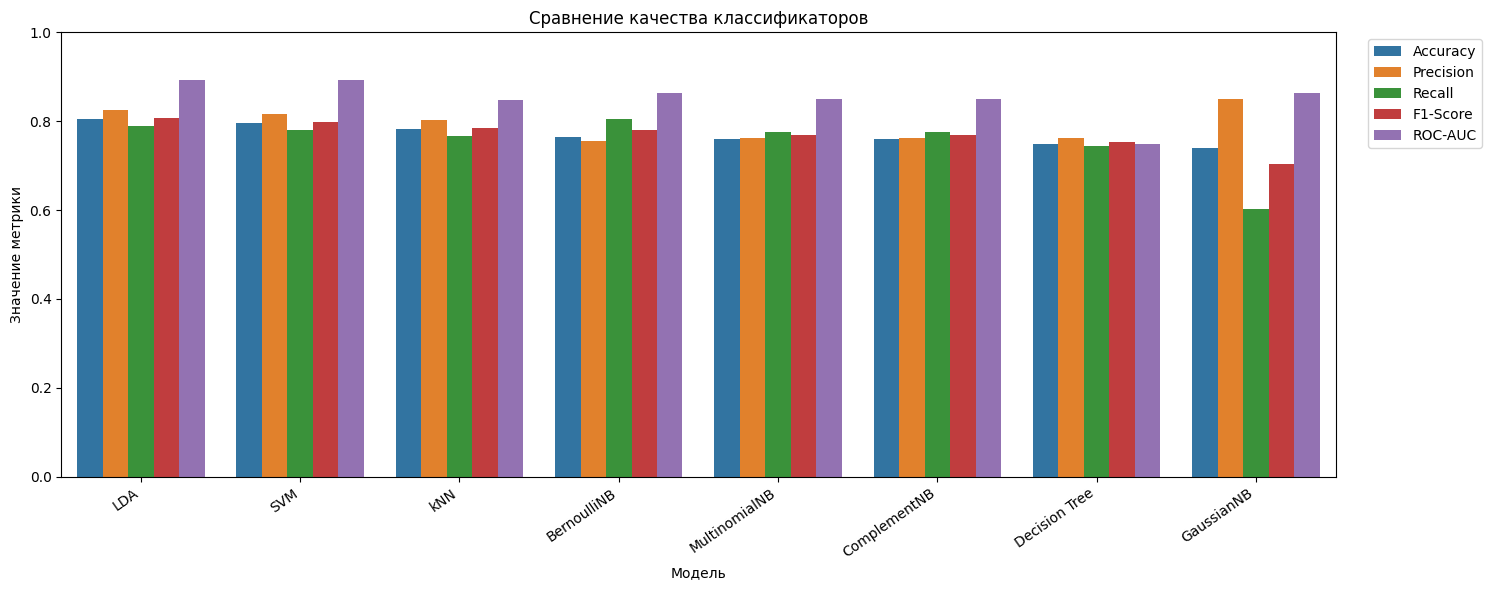

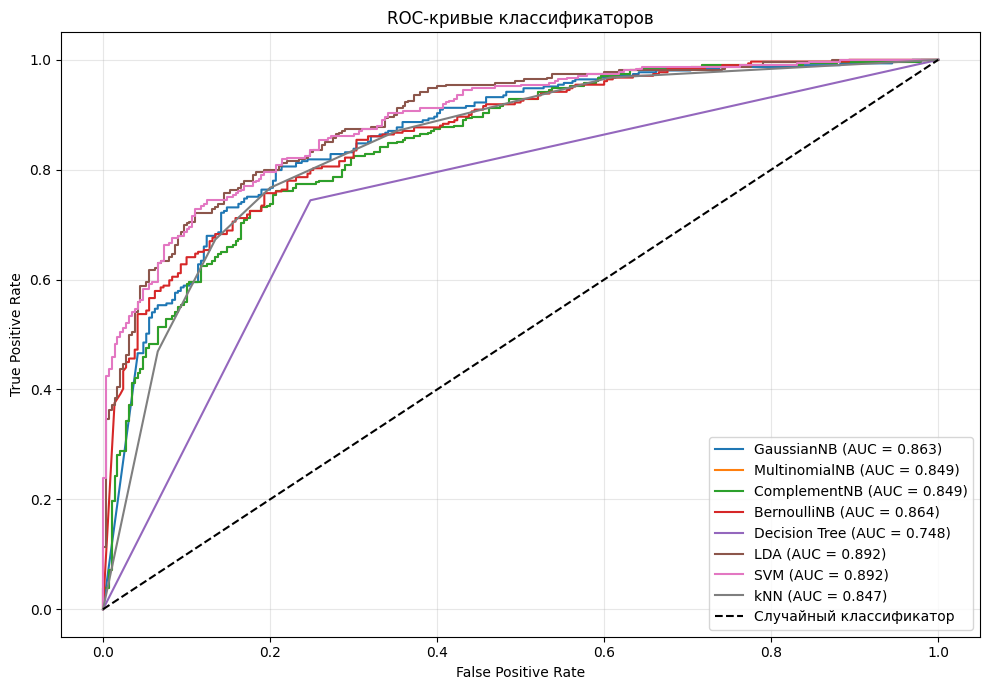

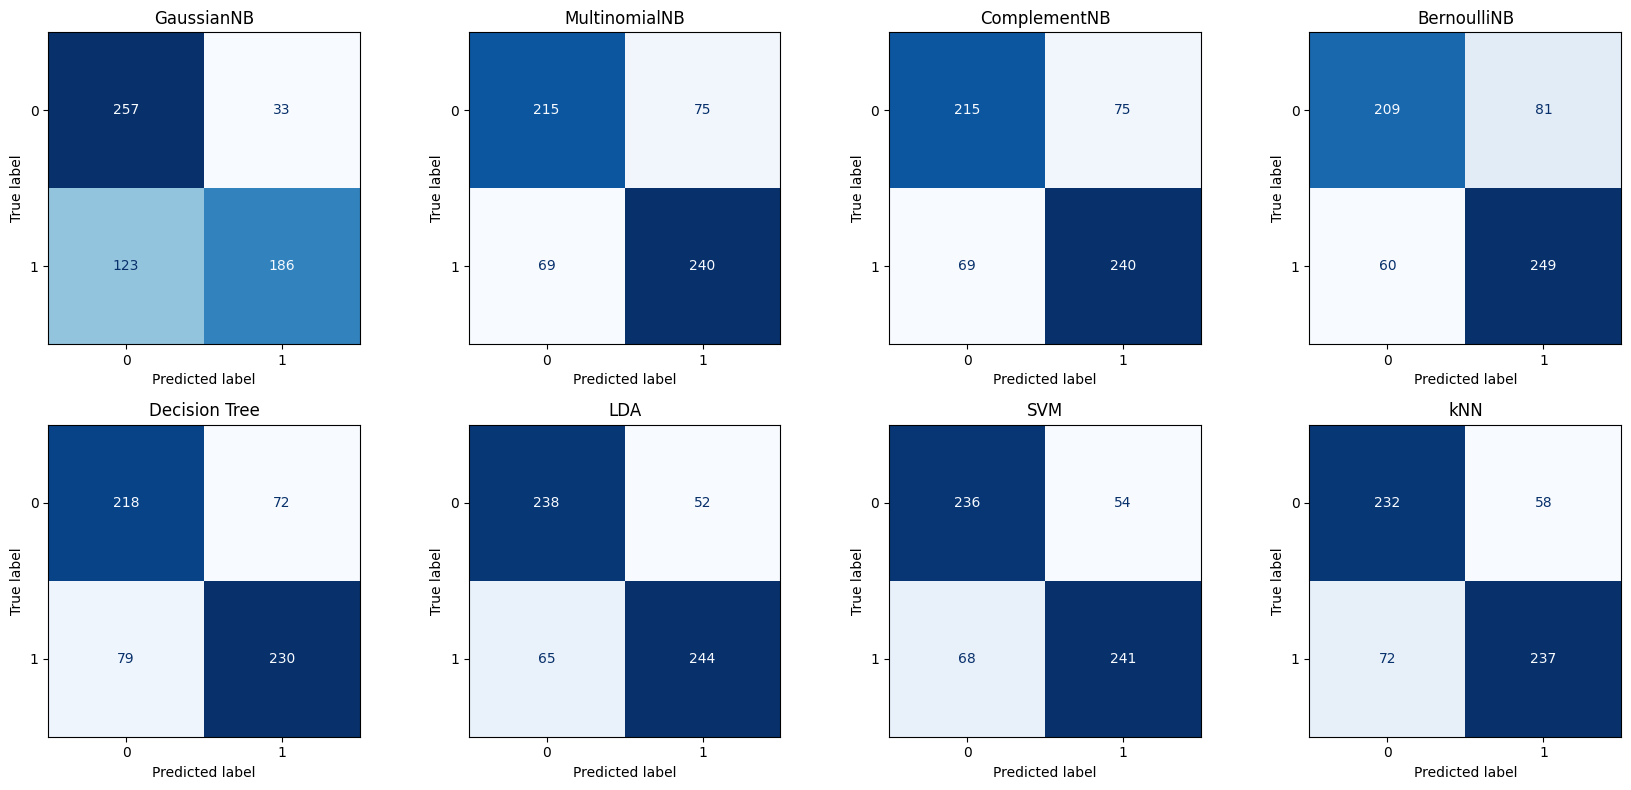


Лучший классификатор по F1-Score: LDA
F1-Score: 0.8066


In [2]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    ConfusionMatrixDisplay
)

def calculate_metrics(model, X, y):

    y_pred = model.predict(X)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X)[:, 1]
    else:
        y_score = model.decision_function(X)

    return {
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(y, y_pred, zero_division=0),
        "Recall": recall_score(y, y_pred, zero_division=0),
        "F1-Score": f1_score(y, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, y_score)
    }

results = []

for name, model in models.items():
    metrics = calculate_metrics(model, X_test, y_test)
    results.append({"Модель": name, **metrics})

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "F1-Score", ascending=False
)

print("СРАВНЕНИЕ КЛАССИФИКАТОРОВ")
display(results_df.round(4))

metrics_plot = results_df.melt(
    id_vars="Модель",
    var_name="Метрика",
    value_name="Значение"
)

plt.figure(figsize=(15, 6))

sns.barplot(
    data=metrics_plot,
    x="Модель",
    y="Значение",
    hue="Метрика"
)

plt.title("Сравнение качества классификаторов")
plt.ylabel("Значение метрики")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))

for name, model in models.items():

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_value = roc_auc_score(y_test, y_score)

    plt.plot(
        fpr, tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "k--", label="Случайный классификатор"
)

plt.title("ROC-кривые классификаторов")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(17, 8))

for ax, (name, model) in zip(axes.flat, models.items()):

    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

best_model_name = results_df.iloc[0]["Модель"]

print("\nЛучший классификатор по F1-Score:", best_model_name)
print(
    "F1-Score:",
    round(results_df.iloc[0]["F1-Score"], 4)
)

По метрикам лучший исходный результат показывает *LDA*: Accuracy = 0,8047, F1-Score = 0,8066 и ROC-AUC = 0,8921. Очень близок SVM с F1-Score = 0,7980 и ROC-AUC = 0,8920. Это означает, что обе модели хорошо разделяют два класса.

Столбчатая диаграмма показывает, что LDA, SVM и kNN имеют наиболее равномерные значения Accuracy, Precision и Recall. У GaussianNB наблюдается другой профиль: самая высокая Precision (0,8493) сочетается с самой низкой Recall (0,6019). Следовательно, модель сравнительно редко ошибочно относит объект к высокому уровню преступности

ROC-кривые всех моделей проходят выше диагонали случайного классификатора. Наибольшая площадь под кривой получена у LDA и SVM, поэтому эти модели лучше остальных ранжируют объекты независимо от конкретного порога решения.

Матрицы ошибок уточняют различия моделей, далее делаем вывод что *LDA выбрана лучшей исходной моделью по F1-Score 0,8066*.

## 3. Настройка гиперпараметров классификационных моделей

Качество классификации зависит не только от выбранного алгоритма, но и от значений его гиперпараметров, определяющих особенности обучения и сложность модели.

Для исследования их влияния используется метод поиска по сетке `GridSearchCV`, который последовательно проверяет заданные комбинации параметров и оценивает качество каждой конфигурации методом кросс-валидации.

Применяется пятикратная стратифицированная кросс-валидация `StratifiedKFold`, обеспечивающая сохранение приблизительного соотношения классов в обучающих и валидационных частях выборки.

В ходе экспериментов исследуются следующие гиперпараметры:

- **GaussianNB:** параметр сглаживания дисперсии `var_smoothing`.
- **MultinomialNB:** параметр сглаживания `alpha`.
- **ComplementNB:** параметры `alpha` и `norm`.
- **BernoulliNB:** параметр `alpha` и порог бинаризации признаков.
- **Decision Tree:** максимальная глубина дерева `max_depth`, минимальное количество объектов для разделения `min_samples_split`, минимальное количество объектов в листе `min_samples_leaf`.
- **LDA:** алгоритм вычислений `solver` и коэффициент регуляризации `shrinkage`.
- **SVM:** коэффициент регуляризации `C`, тип ядра `kernel` и параметр ядра `gamma`.
- **kNN:** количество соседей `n_neighbors`, способ взвешивания `weights` и параметр метрики расстояния `p`.


Настройка: GaussianNB
Лучшие параметры: {'model__var_smoothing': 1e-07}
F1 на CV: 0.7444

Настройка: MultinomialNB
Лучшие параметры: {'model__alpha': 0.1}
F1 на CV: 0.7918

Настройка: ComplementNB
Лучшие параметры: {'model__alpha': 0.1, 'model__norm': False}
F1 на CV: 0.7918

Настройка: BernoulliNB
Лучшие параметры: {'binary__threshold': 0.0, 'model__alpha': 0.1}
F1 на CV: 0.8044

Настройка: Decision Tree
Лучшие параметры: {'model__max_depth': 5, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
F1 на CV: 0.7964

Настройка: LDA
Лучшие параметры: {'model__shrinkage': 0.5, 'model__solver': 'lsqr'}
F1 на CV: 0.8391

Настройка: SVM
Лучшие параметры: {'model__C': 0.1, 'model__kernel': 'linear'}
F1 на CV: 0.8439

Настройка: kNN
Лучшие параметры: {'model__n_neighbors': 15, 'model__p': 2, 'model__weights': 'uniform'}
F1 на CV: 0.8193

СРАВНЕНИЕ ДО И ПОСЛЕ НАСТРОЙКИ


,Модель,CV F1,F1 до,F1 после,ROC-AUC до,ROC-AUC после
0,GaussianNB,0.7444,0.7045,0.7045,0.8629,0.8629
1,MultinomialNB,0.7918,0.7692,0.7712,0.8493,0.8504
2,ComplementNB,0.7918,0.7692,0.7712,0.8493,0.8504
3,BernoulliNB,0.8044,0.7793,0.7793,0.8645,0.8640
4,Decision Tree,0.7964,0.7529,0.7883,0.7480,0.8088
5,LDA,0.8391,0.8066,0.7947,0.8921,0.8919
6,SVM,0.8439,0.7980,0.8144,0.8920,0.8961
7,kNN,0.8193,0.7848,0.7960,0.8474,0.8779


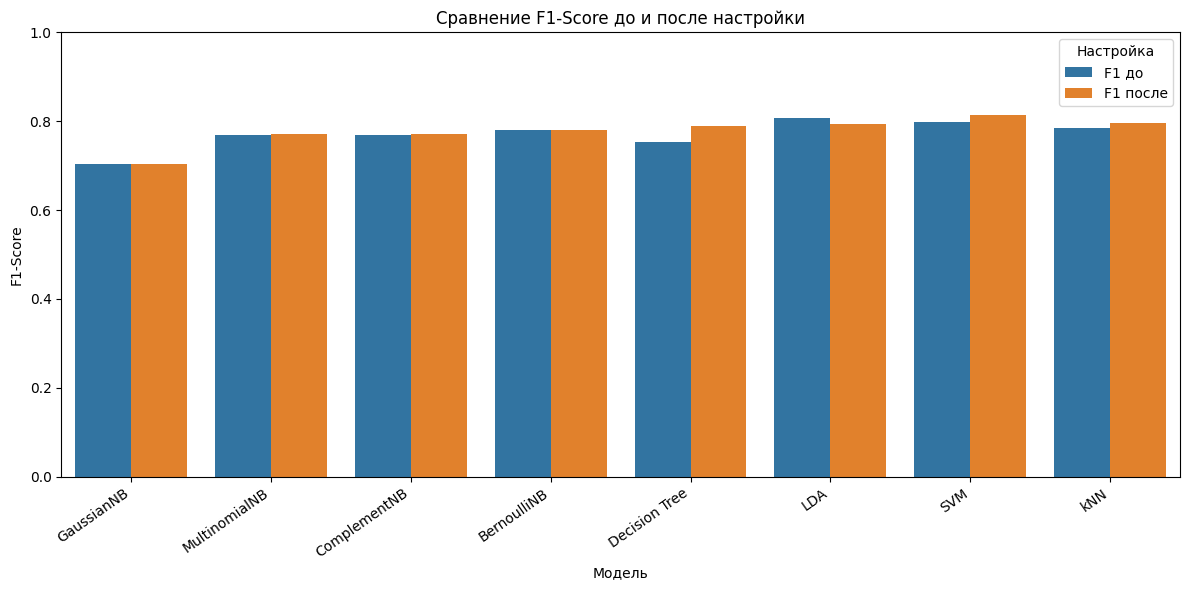

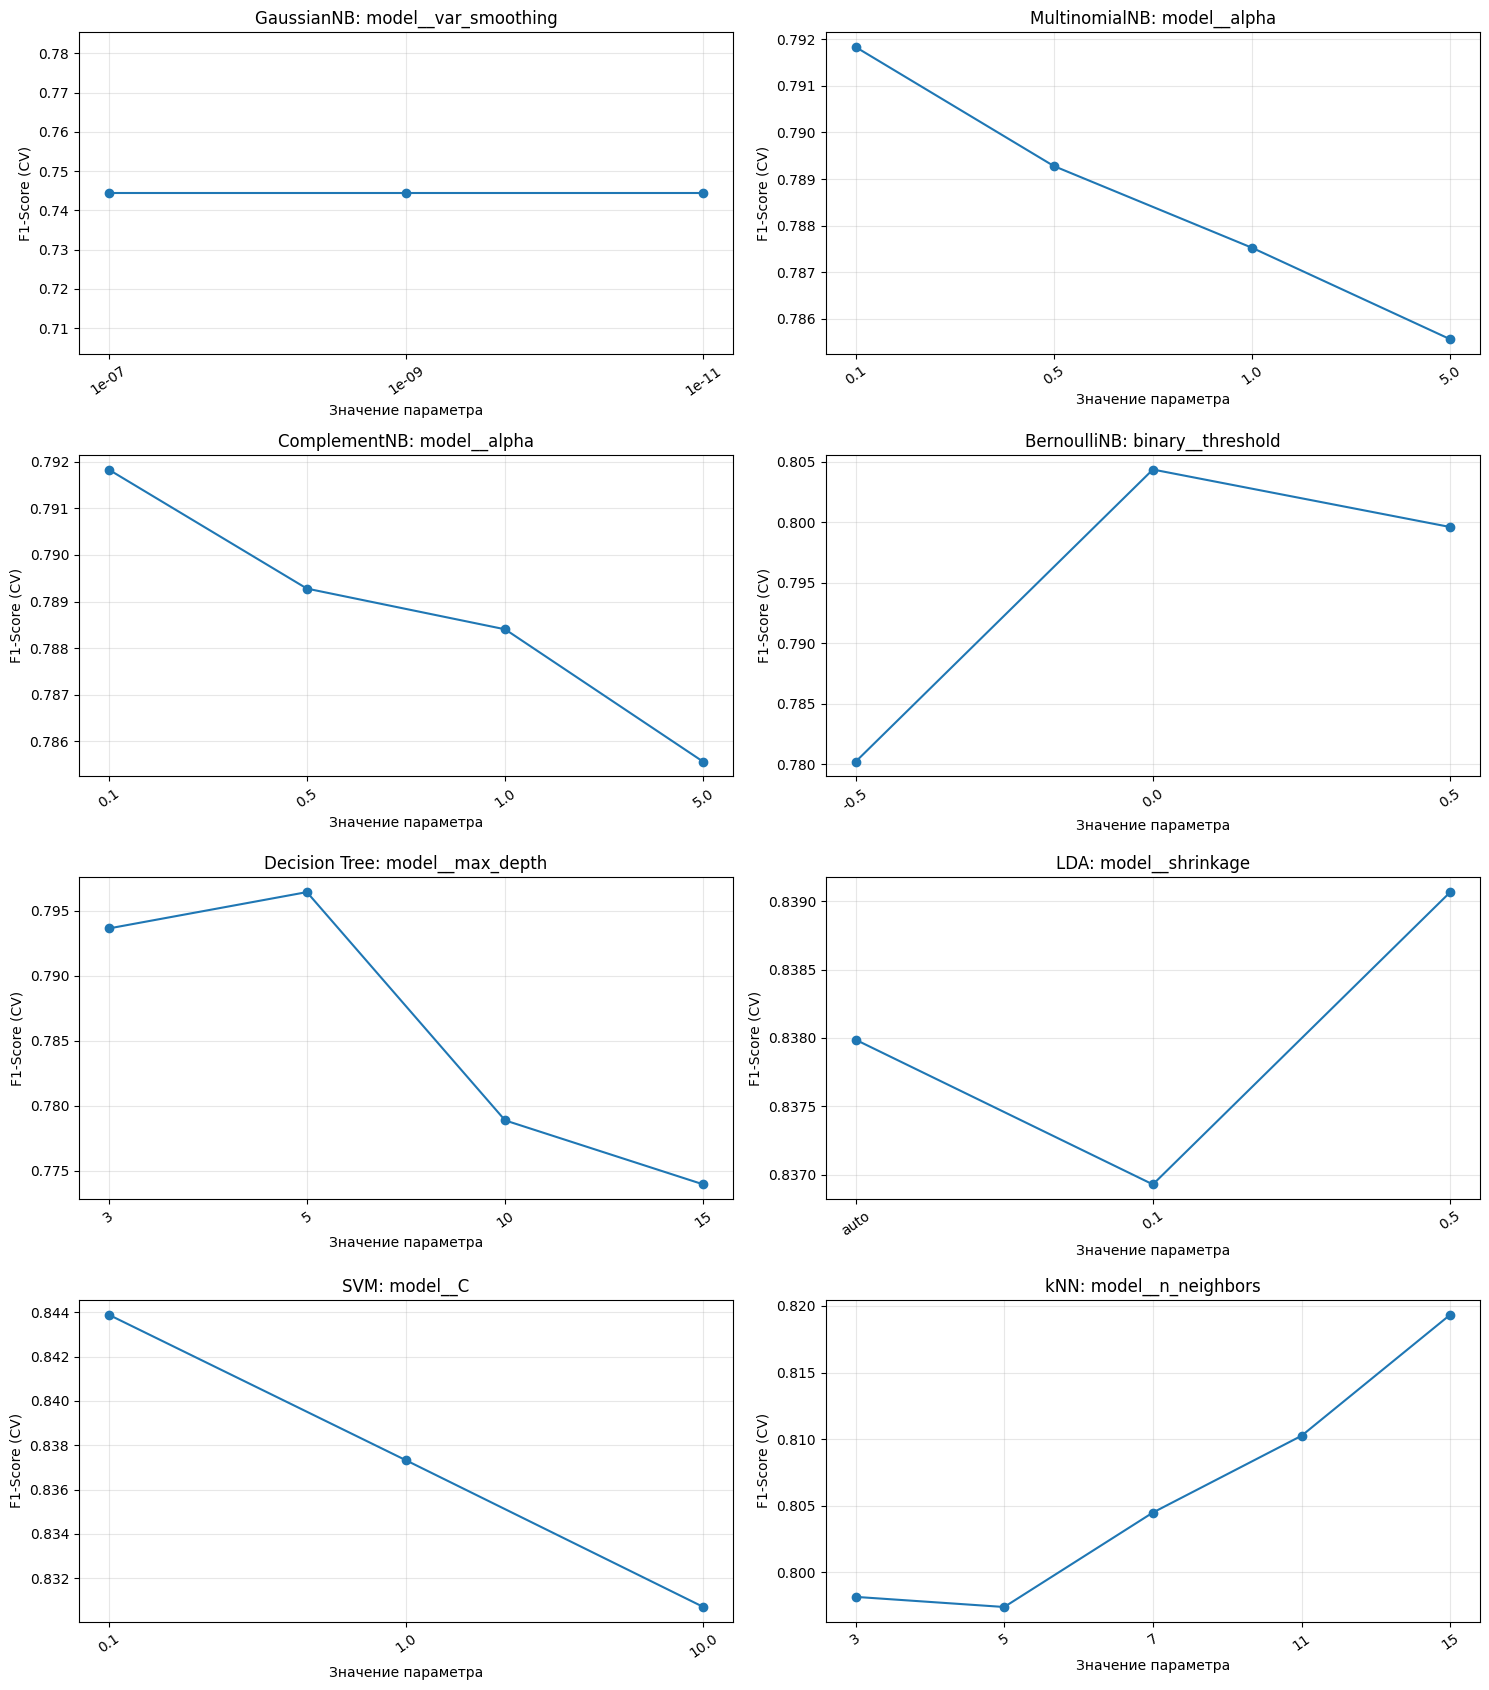


МЕТРИКИ ПОСЛЕ НАСТРОЙКИ


,Модель,Accuracy,Precision,Recall,F1-Score,ROC-AUC
6,SVM,0.8114,0.8267,0.8026,0.8144,0.8961
7,kNN,0.7947,0.8163,0.7767,0.7960,0.8779
5,LDA,0.7913,0.8067,0.7832,0.7947,0.8919
4,Decision Tree,0.7830,0.7934,0.7832,0.7883,0.8088
3,BernoulliNB,0.7646,0.7545,0.8058,0.7793,0.8640
1,MultinomialNB,0.7613,0.7627,0.7799,0.7712,0.8504
2,ComplementNB,0.7613,0.7627,0.7799,0.7712,0.8504
0,GaussianNB,0.7396,0.8493,0.6019,0.7045,0.8629


In [3]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.base import clone

param_grids = {
    "GaussianNB": {
        "model__var_smoothing": [1e-7, 1e-9, 1e-11]
    },

    "MultinomialNB": {
        "model__alpha": [0.1, 0.5, 1, 5]
    },

    "ComplementNB": {
        "model__alpha": [0.1, 0.5, 1, 5],
        "model__norm": [True, False]
    },

    "BernoulliNB": {
        "model__alpha": [0.1, 0.5, 1, 5],
        "binary__threshold": [-0.5, 0.0, 0.5]
    },

    "Decision Tree": {
        "model__max_depth": [3, 5, 10, 15, None],
        "model__min_samples_split": [2, 5, 10],
        "model__min_samples_leaf": [1, 3, 5]
    },

    "LDA": [
        {"model__solver": ["svd"]},
        {
            "model__solver": ["lsqr"],
            "model__shrinkage": [None, "auto", 0.1, 0.5]
        }
    ],

    "SVM": [
        {
            "model__C": [0.1, 1, 10],
            "model__kernel": ["linear"]
        },
        {
            "model__C": [0.1, 1, 10],
            "model__kernel": ["rbf"],
            "model__gamma": ["scale", 0.01, 0.1]
        }
    ],

    "kNN": {
        "model__n_neighbors": [3, 5, 7, 11, 15],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2]
    }
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

best_models = {}
tuning_results = {}
comparison = []

for name, model in models.items():

    print(f"\nНастройка: {name}")

    grid_search = GridSearchCV(
        estimator=clone(model),
        param_grid=param_grids[name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        return_train_score=True
    )

    grid_search.fit(X_train, y_train)

    best_models[name] = grid_search.best_estimator_
    tuning_results[name] = pd.DataFrame(
        grid_search.cv_results_
    )

    initial_metrics = calculate_metrics(
        model, X_test, y_test
    )

    tuned_metrics = calculate_metrics(
        grid_search.best_estimator_, X_test, y_test
    )

    comparison.append({
        "Модель": name,
        "CV F1": grid_search.best_score_,
        "F1 до": initial_metrics["F1-Score"],
        "F1 после": tuned_metrics["F1-Score"],
        "ROC-AUC до": initial_metrics["ROC-AUC"],
        "ROC-AUC после": tuned_metrics["ROC-AUC"]
    })

    print("Лучшие параметры:", grid_search.best_params_)
    print("F1 на CV:", round(grid_search.best_score_, 4))

comparison_df = pd.DataFrame(comparison)

print("\nСРАВНЕНИЕ ДО И ПОСЛЕ НАСТРОЙКИ")
display(comparison_df.round(4))

plot_df = comparison_df.melt(
    id_vars="Модель",
    value_vars=["F1 до", "F1 после"],
    var_name="Настройка",
    value_name="F1-Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Модель",
    y="F1-Score",
    hue="Настройка"
)

plt.title("Сравнение F1-Score до и после настройки")
plt.ylim(0, 1)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

parameters_to_plot = {
    "GaussianNB": "model__var_smoothing",
    "MultinomialNB": "model__alpha",
    "ComplementNB": "model__alpha",
    "BernoulliNB": "binary__threshold",
    "Decision Tree": "model__max_depth",
    "LDA": "model__shrinkage",
    "SVM": "model__C",
    "kNN": "model__n_neighbors"
}

fig, axes = plt.subplots(4, 2, figsize=(15, 17))

for ax, (name, parameter) in zip(
    axes.flat, parameters_to_plot.items()
):

    df_cv = tuning_results[name].copy()

    column = "param_" + parameter

    if column not in df_cv.columns:
        continue

    df_cv = df_cv[df_cv[column].notna()].copy()
    df_cv["Значение"] = df_cv[column].astype(str)

    grouped = (
        df_cv.groupby("Значение", sort=False)
        ["mean_test_score"].max()
    )

    ax.plot(grouped.index, grouped.values, marker="o")
    ax.set_title(f"{name}: {parameter}")
    ax.set_xlabel("Значение параметра")
    ax.set_ylabel("F1-Score (CV)")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

tuned_results = []

for name, model in best_models.items():

    metrics = calculate_metrics(model, X_test, y_test)
    tuned_results.append({"Модель": name, **metrics})

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df = tuned_results_df.sort_values(
    "F1-Score", ascending=False
)

print("\nМЕТРИКИ ПОСЛЕ НАСТРОЙКИ")
display(tuned_results_df.round(4))

Подбор гиперпараметров снизил переобучение и улучшил качество большинства алгоритмов.
- Дерево решений: заметно улучшилось (F1 до 0,788, ROC-AUC до 0,809) благодаря ограничению глубины до 5 уровней.

- SVM: стал абсолютным лидером (F1 = 0,8144, ROC-AUC = 0,8961). Лучший вариант: линейное ядро и C = 0,1 (оптимальная регуляризация).
kNN: улучшился (F1 до 0,796) при использовании 15 соседей.

- Наивный Байес: дал небольшой прирост при alpha = 0,1. GaussianNB к настройке нечувствителен.

- LDA: качество на тесте чуть снизилось, что нормально, так как параметры выбирались по кросс-валидации, а не по тестовой выборке.

## 4. Разработка и исследование нейронной сети на TensorFlow

Бинарной классификации на TensorFlow/Keras.
- Обучение: оптимизатор Adam, функция потерь Binary Crossentropy, мини-батчи.
- Метрики: Accuracy, F1, ROC-AUC.
- Данные делятся на обучающую и валидационную выборки (80/20). Пропуски заполняются медианой, признаки стандартизируются.
- Подбираются гиперпараметры. Базовая конфигурация: 2 скрытых слоя (64 и 32 нейрона, ReLU), Adam (lr=0.001), 50 эпох, batch=32. Процесс логируется в TensorBoard.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from pathlib import Path

tf.keras.utils.set_random_seed(42)

X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

imputer_nn = SimpleImputer(strategy="median")
scaler_nn = StandardScaler()

X_nn_train = imputer_nn.fit_transform(X_nn_train)
X_nn_val = imputer_nn.transform(X_nn_val)
X_nn_test = imputer_nn.transform(X_test)

X_nn_train = scaler_nn.fit_transform(X_nn_train).astype("float32")
X_nn_val = scaler_nn.transform(X_nn_val).astype("float32")
X_nn_test = scaler_nn.transform(X_nn_test).astype("float32")

y_nn_train = np.asarray(y_nn_train, dtype="float32")
y_nn_val = np.asarray(y_nn_val, dtype="float32")

def create_network(
    input_dim,
    hidden_layers=(64, 32),
    activation="relu",
    learning_rate=0.001
):

    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    for neurons in hidden_layers:
        model.add(layers.Dense(neurons, activation=activation))

    model.add(layers.Dense(1, activation="sigmoid"))

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.AUC(name="auc")
        ]
    )

    return model

base_config = {
    "hidden_layers": (64, 32),
    "activation": "relu",
    "learning_rate": 0.001,
    "epochs": 50,
    "batch_size": 32
}

experiments = {
    "Базовая модель": {},

    "1 скрытый слой": {
        "hidden_layers": (64,)
    },

    "3 скрытых слоя": {
        "hidden_layers": (128, 64, 32)
    },

    "Меньше нейронов": {
        "hidden_layers": (32, 16)
    },

    "Активация tanh": {
        "activation": "tanh"
    },

    "20 эпох": {
        "epochs": 20
    },

    "80 эпох": {
        "epochs": 80
    },

    "Batch 16": {
        "batch_size": 16
    },

    "Batch 64": {
        "batch_size": 64
    },

    "Learning rate 0.0001": {
        "learning_rate": 0.0001
    }
}

histories = {}
nn_models = {}
nn_results = []

log_dir = Path("logs/classification")

for i, (name, changes) in enumerate(experiments.items()):

    config = {**base_config, **changes}

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(42)

    model = create_network(
        input_dim=X_nn_train.shape[1],
        hidden_layers=config["hidden_layers"],
        activation=config["activation"],
        learning_rate=config["learning_rate"]
    )

    callbacks = [
        keras.callbacks.TensorBoard(
            log_dir=str(log_dir / f"experiment_{i:02d}"),
            histogram_freq=1
        )
    ]

    history = model.fit(
        X_nn_train,
        y_nn_train,
        validation_data=(X_nn_val, y_nn_val),
        epochs=config["epochs"],
        batch_size=config["batch_size"],
        callbacks=callbacks,
        verbose=0
    )

    histories[name] = history
    nn_models[name] = model

    val_prob = model.predict(
        X_nn_val, verbose=0
    ).ravel()

    val_pred = (val_prob >= 0.5).astype(int)

    nn_results.append({
        "Эксперимент": name,
        "Слои": str(config["hidden_layers"]),
        "Активация": config["activation"],
        "Эпохи": config["epochs"],
        "Batch": config["batch_size"],
        "Learning rate": config["learning_rate"],
        "Accuracy": accuracy_score(y_nn_val, val_pred),
        "F1-Score": f1_score(y_nn_val, val_pred),
        "ROC-AUC": roc_auc_score(y_nn_val, val_prob)
    })

    print(f"Завершён эксперимент: {name}")

nn_results_df = pd.DataFrame(nn_results)

nn_results_df = nn_results_df.sort_values(
    "ROC-AUC", ascending=False
)

print("\nСРАВНЕНИЕ КОНФИГУРАЦИЙ НЕЙРОСЕТИ")
display(nn_results_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name, history in histories.items():

    axes[0].plot(
        history.history["loss"],
        label=name
    )

    axes[1].plot(
        history.history["val_loss"],
        label=name
    )

axes[0].set_title("Потери на обучающей выборке")
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)

axes[1].set_title("Потери на валидационной выборке")
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Validation Loss")
axes[1].grid(alpha=0.3)

fig.legend(
    loc="outside lower center",
    ncol=3
)
plt.tight_layout(rect=[0, 0.14, 1, 1])
plt.show()

best_nn_name = nn_results_df.iloc[0]["Эксперимент"]
best_nn = nn_models[best_nn_name]
best_history = histories[best_nn_name]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    best_history.history["loss"],
    label="Обучение"
)
axes[0].plot(
    best_history.history["val_loss"],
    label="Валидация"
)

axes[0].set_title("Функция потерь")
axes[0].set_xlabel("Эпоха")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    best_history.history["accuracy"],
    label="Обучение"
)
axes[1].plot(
    best_history.history["val_accuracy"],
    label="Валидация"
)

axes[1].set_title("Accuracy")
axes[1].set_xlabel("Эпоха")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

test_prob = best_nn.predict(
    X_nn_test, verbose=0
).ravel()

test_pred = (test_prob >= 0.5).astype(int)

nn_metrics = {
    "Accuracy": accuracy_score(y_test, test_pred),
    "Precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(y_test, test_prob)
}

print("\nЛучшая нейросеть:", best_nn_name)
display(pd.DataFrame([nn_metrics]).round(4))

final_results = pd.concat([
    tuned_results_df,
    pd.DataFrame([{
        "Модель": "TensorFlow: " + best_nn_name,
        **nn_metrics
    }])
], ignore_index=True)

final_results = final_results.sort_values(
    "F1-Score", ascending=False
)

print("\nИТОГОВОЕ СРАВНЕНИЕ")
display(final_results.round(4))


Завершён эксперимент: Базовая модель

Завершён эксперимент: 1 скрытый слой


![1](img/1.png)
Рисунок 1 – Изменение точности классификации нейронной сети на обучающей выборке в процессе обучения.

![2](img/2.png)
Рисунок 2 – Изменение точности классификации нейронной сети на валидационной выборке в процессе обучения.

![3](img/3.png)
Рисунок 3 – Изменение функции потерь нейронной сети на обучающей выборке в процессе обучения.

![4](img/4.png)
Рисунок 4 – Изменение функции потерь нейронной сети на валидационной выборке в процессе обучения.

- Лучшая конфигурация: уменьшенная скорость обучения (lr = 0.0001). Она дала максимальный ROC-AUC на валидации (0,9007) и обучалась стабильно, без резкого переобучения.

- Признаки переобучения: Усложнение сети (3 слоя) или увеличение времени обучения (80 эпох) ухудшили результат. Модель начала «запоминать» обучающие данные, но хуже работать на новых.

- Результат на тесте: F1-Score = 0,797, ROC-AUC = 0,890. Небольшое снижение качества относительно валидации абсолютно ожидаемо.

- Настроенный SVM остался абсолютным лидером (F1 = 0,814, ROC-AUC = 0,896). Нейросеть заняла лишь второе место, немного опередив kNN и LDA.

- Для данного объема табличных данных сложная нейросеть не дала преимущества перед классическим линейным SVM.